<a href="https://colab.research.google.com/github/gflamiano/SJU-CSC-672-ML/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 6

#### **Task 1: Dataset Loading and Dimensionality Inspection** Load the Olivetti Faces dataset using sklearn.datasets.fetch_olivetti_faces. Print the total number of samples, unique target subjects, feature dimensions, and plot a 4 x 5 grid of sample faces labeled with their subject IDs.

This cell loads the Olivetti Faces dataset and inspects its dimensions, then displays sample images. It does this in five steps:

1. Import libraries. `numpy` handles numerical arrays, `matplotlib.pyplot` creates the plots, and `fetch_olivetti_faces` from scikit-learn downloads the dataset.
2. Download the data. `fetch_olivetti_faces(shuffle=True, random_state=42)` downloads the dataset the first time it runs and caches it locally. `shuffle=True` mixes the order of the images so that the first 20 faces come from different subjects, and `random_state=42` makes that shuffle the same every run.
3. Separate the data into three parts. `X` is the feature matrix, where each row is one face flattened into a 4,096-value vector of pixel intensities. `y` holds the subject ID (0 to 39) for each face. `images` stores the same faces as 64 x 64 grids, which is the shape needed for displaying them.
4. Print the dimensions. The cell reports the total number of samples (400), the number of unique subjects (40), the shape of `X` (400 x 4,096), the shape of `y`, and the original image size (64 x 64). This shows that each image has 4,096 features, which is far more features than the 400 samples we have.
5. Plot a grid of sample faces. `plt.subplots(4, 5)` creates a grid of 20 panels. A loop displays one face in each panel using `cmap='gray'` (the images are grayscale), titles it with its subject ID, and hides the axes. The grid lets us see how the same person can look different across photos and how different people share a similar layout.

Total number of samples: 400
Unique target subjects: 40
Feature matrix shape (X): (400, 4096)
Target labels shape (y): (400,)
Number of features per instance (Dimensions): 4096
Original image shape: 64x64


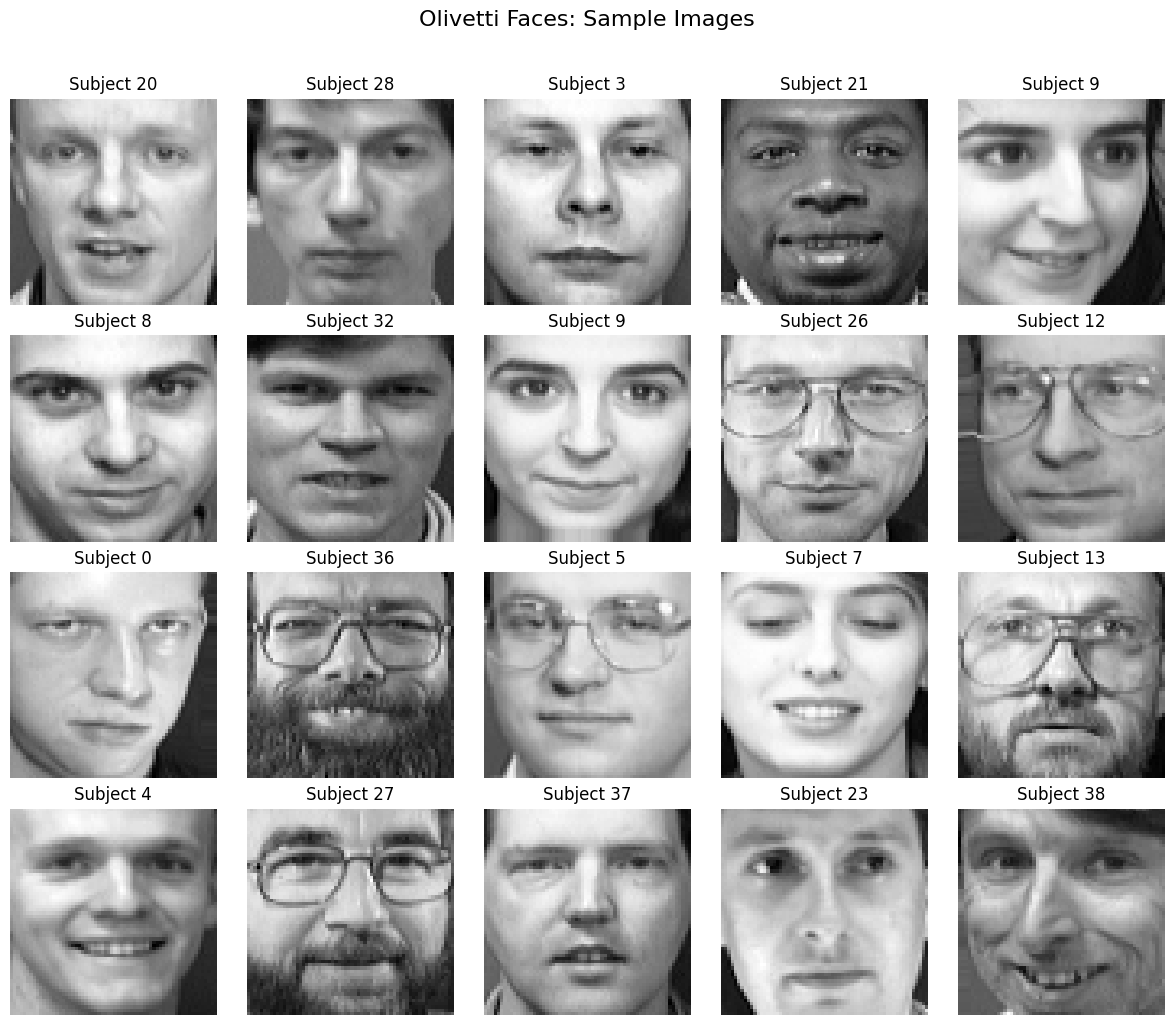

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

# Load the Olivetti Faces dataset
faces = fetch_olivetti_faces(shuffle=True, random_state=42)

X = faces.data
y = faces.target
images = faces.images

# Dimensionality inspection
print(f"Total number of samples: {X.shape[0]}")
print(f"Unique target subjects: {len(np.unique(y))}")
print(f"Feature matrix shape (X): {X.shape}")
print(f"Target labels shape (y): {y.shape}")
print(f"Number of features per instance (Dimensions): {X.shape[1]}")
print(f"Original image shape: {images.shape[1]}x{images.shape[2]}")

# Plot a 4 x 5 grid of sample faces labeled with subject IDs
fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i], cmap='gray')
    ax.set_title(f'Subject {y[i]}')
    ax.axis('off')

plt.suptitle('Olivetti Faces: Sample Images', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

#### **Task 2: Cumulative Explained Variance & Elbow Plot** Fit a full PCA model on the dataset. Plot both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components. Determine and print the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.

This cell fits a full PCA model to the faces dataset and measures how much variance each principal component captures. It does this in four steps:

1. Fit PCA. `PCA(n_components=None)` keeps every component, and `.fit(X)` finds the orthogonal directions of maximum variance. Because there are only 400 samples, at most 400 components can be computed, even though each face has 4,096 features.
2. Compute the variance ratios. `explained_variance_ratio_` gives the fraction of total variance captured by each component. `np.cumsum` adds these up to give the cumulative variance after the first 1, 2, 3, ... components.
3. Find the thresholds. For each target (90%, 95%, 99%), `np.argmax(cumulative_variance_ratio >= t)` returns the index of the first component where the cumulative variance reaches that target. We add 1 because Python counts from 0, but the number of components counts from 1.
4. Plot the results. The left panel shows the variance explained by each individual component, and the right panel shows the cumulative curve with dashed lines marking where each threshold is reached.

Number of principal components computed: 400
Variance explained by the first component: 0.2381
Variance explained by the first 2 components: 0.3781

Components required for 90% variance: 66
Components required for 95% variance: 123
Components required for 99% variance: 260


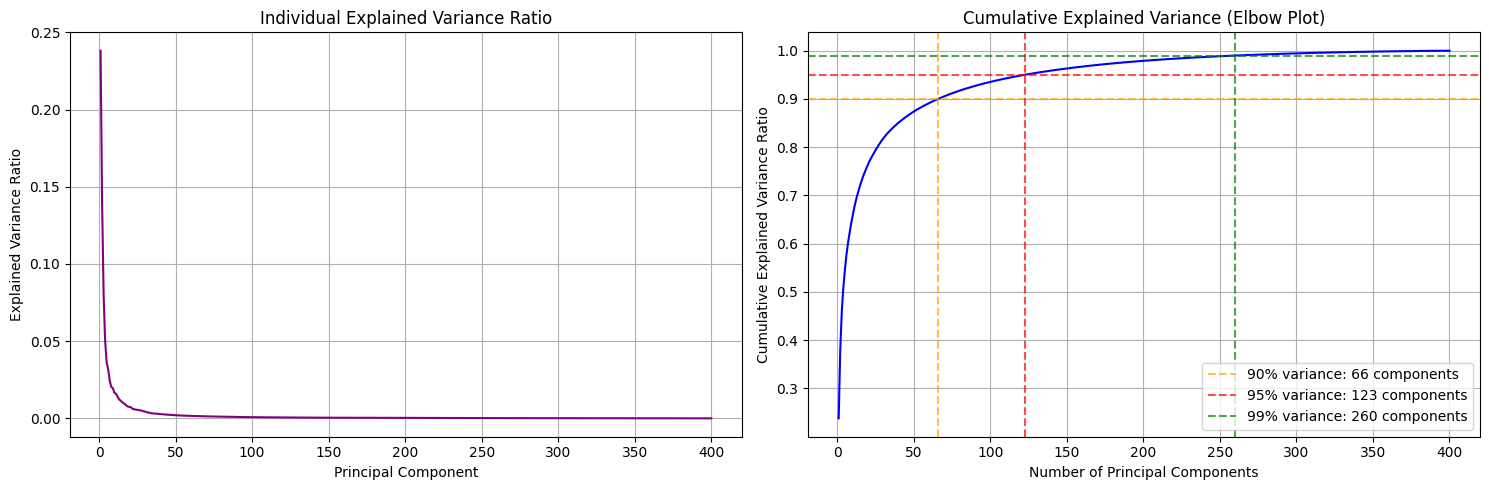

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=None)
pca.fit(X)

explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

print(f"Number of principal components computed: {len(explained_variance_ratio)}")
print(f"Variance explained by the first component: {explained_variance_ratio[0]:.4f}")
print(f"Variance explained by the first 2 components: {cumulative_variance_ratio[1]:.4f}\n")

thresholds = [0.90, 0.95, 0.99]
components_needed = {}

for t in thresholds:
    n_comp = np.argmax(cumulative_variance_ratio >= t) + 1
    components_needed[t] = n_comp
    print(f"Components required for {int(t * 100)}% variance: {n_comp}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
component_numbers = np.arange(1, len(explained_variance_ratio) + 1)

axes[0].plot(component_numbers, explained_variance_ratio, color='purple', linewidth=1.5)
axes[0].set_title('Individual Explained Variance Ratio')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].grid(True)

axes[1].plot(component_numbers, cumulative_variance_ratio, color='b', linewidth=1.5)
colors = ['orange', 'red', 'green']
for t, c in zip(thresholds, colors):
    axes[1].axhline(y=t, color=c, linestyle='--', alpha=0.7)
    axes[1].axvline(x=components_needed[t], color=c, linestyle='--', alpha=0.7,
                    label=f'{int(t * 100)}% variance: {components_needed[t]} components')

axes[1].set_title('Cumulative Explained Variance (Elbow Plot)')
axes[1].set_xlabel('Number of Principal Components')
axes[1].set_ylabel('Cumulative Explained Variance Ratio')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### **Task 3: Image Compression and Reconstruction Analysis** Select 5 representative facial images. Compress and reconstruct them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}. Plot a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the Mean Squared Error (MSE) between original and reconstructed faces as a function of k.

This cell compresses and reconstructs faces with PCA at several component counts, then measures how much detail is lost. It does this in five steps:

1. Select five faces. `np.where(y == s)[0][0]` finds the first image belonging to each of five different subjects (0, 10, 20, 30, 39), so the sample covers different people rather than five photos of the same one.
2. Loop over component counts. For each $k$ in {10, 50, 100, 200, 300}, a PCA model with `n_components=k` is fitted on the full dataset.
3. Compress and reconstruct. `transform` projects each face onto the first $k$ principal components (compression to $k$ numbers), and `inverse_transform` maps those numbers back to a 4,096-pixel image (reconstruction). Whatever variance sits in the dropped components is lost in this step.
4. Compute the MSE. The mean squared pixel difference between each original and its reconstruction is averaged across the five selected faces. It is also averaged across all 400 faces, which gives a more stable estimate than five images alone.
5. Plot the results. The grid has one row per face, with the original in the first column and one reconstruction per $k$ in the remaining columns. The line plot shows MSE against $k$.

k =  10 | MSE (5 faces): 0.00754 | MSE (all 400 faces): 0.00662
k =  50 | MSE (5 faces): 0.00275 | MSE (all 400 faces): 0.00244
k = 100 | MSE (5 faces): 0.00147 | MSE (all 400 faces): 0.00125
k = 200 | MSE (5 faces): 0.00031 | MSE (all 400 faces): 0.00041
k = 300 | MSE (5 faces): 0.00008 | MSE (all 400 faces): 0.00011


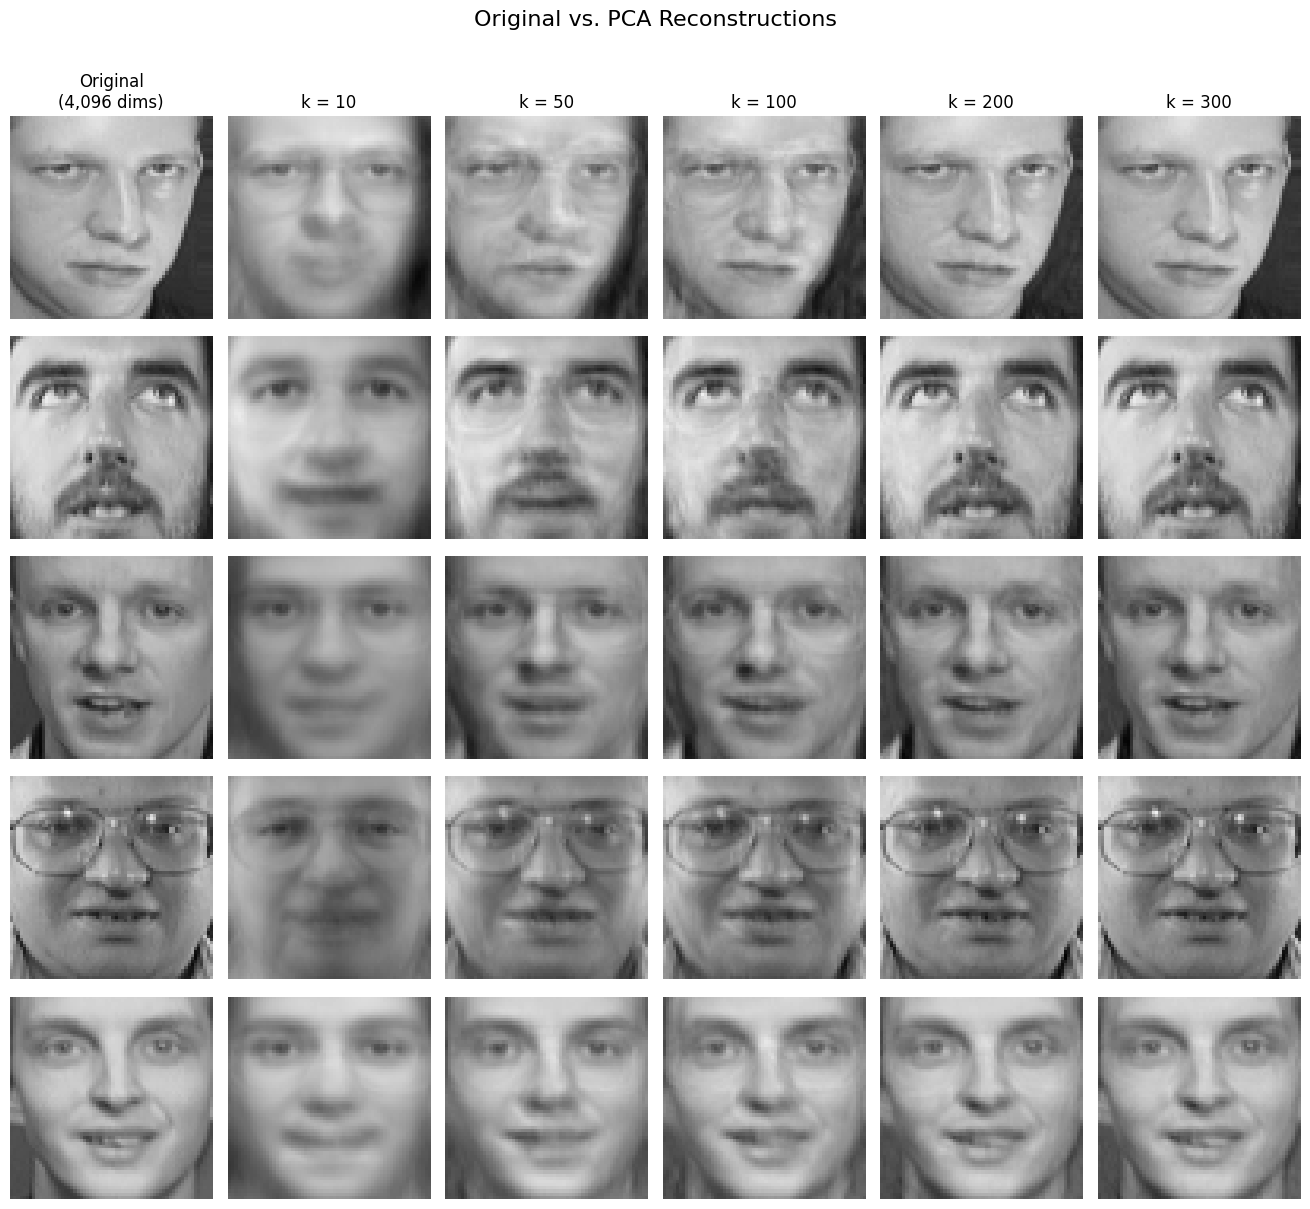

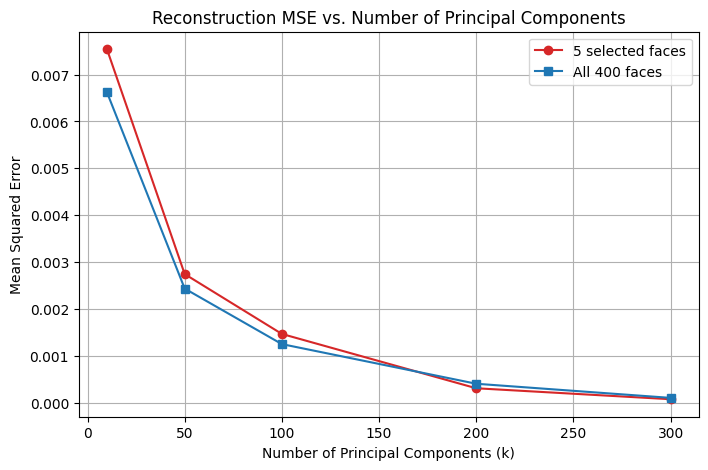

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

subject_ids = [0, 10, 20, 30, 39]
sample_idx = [np.where(y == s)[0][0] for s in subject_ids]

X_samples = X[sample_idx]
k_values = [10, 50, 100, 200, 300]

reconstructions = {}
mse_samples = []
mse_all = []

for k in k_values:
    pca_k = PCA(n_components=k)
    pca_k.fit(X)

    X_rec_samples = pca_k.inverse_transform(pca_k.transform(X_samples))
    reconstructions[k] = X_rec_samples

    X_rec_all = pca_k.inverse_transform(pca_k.transform(X))

    mse_samples.append(np.mean((X_samples - X_rec_samples) ** 2))
    mse_all.append(np.mean((X - X_rec_all) ** 2))

    print(f"k = {k:>3} | MSE (5 faces): {mse_samples[-1]:.5f} | MSE (all 400 faces): {mse_all[-1]:.5f}")

n_rows = len(sample_idx)
n_cols = len(k_values) + 1
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.4 * n_rows))

for r in range(n_rows):
    axes[r, 0].imshow(X_samples[r].reshape(64, 64), cmap='gray', vmin=0, vmax=1)
    axes[r, 0].axis('off')
    if r == 0:
        axes[r, 0].set_title('Original\n(4,096 dims)')

    for c, k in enumerate(k_values, start=1):
        rec_img = np.clip(reconstructions[k][r], 0, 1).reshape(64, 64)
        axes[r, c].imshow(rec_img, cmap='gray', vmin=0, vmax=1)
        axes[r, c].axis('off')
        if r == 0:
            axes[r, c].set_title(f'k = {k}')

plt.suptitle('Original vs. PCA Reconstructions', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(k_values, mse_samples, marker='o', color='tab:red', label='5 selected faces')
plt.plot(k_values, mse_all, marker='s', color='tab:blue', label='All 400 faces')
plt.title('Reconstruction MSE vs. Number of Principal Components')
plt.xlabel('Number of Principal Components (k)')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.show()

#### **Task 4: Visualization of "Eigenfaces"** Extract the principal components (eigenvectors) from your fitted PCA model. Reshape the first 15 principal components back into 64 x 64 grids and visualize them in a 3 x 5  plot grid ("Eigenfaces"). Annotate each plot with the percentage of total variance explained by that specific component.

This cell extracts the first 15 principal components from the fitted PCA model and displays them as images. It does this in four steps:

1. Extract the components. `pca.components_` is a matrix where each row is one principal component, a 4,096-value vector with one weight per pixel. We reuse the full PCA model fitted in Section 2.
2. Convert the variance ratios to percentages. `explained_variance_ratio_` gives the fraction of total variance each component captures. Multiplying by 100 turns it into a percentage for the plot titles.
3. Reshape each component. `reshape(64, 64)` turns the 4,096-value vector back into a square grid so it can be viewed as an image. Each pixel's brightness shows how strongly that pixel contributes to the component.
4. Plot the grid. `plt.subplots(3, 5)` creates 15 panels, one per eigenface. Each panel is titled with its component number and the share of total variance it explains, and the axes are hidden.

Shape of components matrix: (400, 4096)
Variance explained by the first 15 components: 72.12%


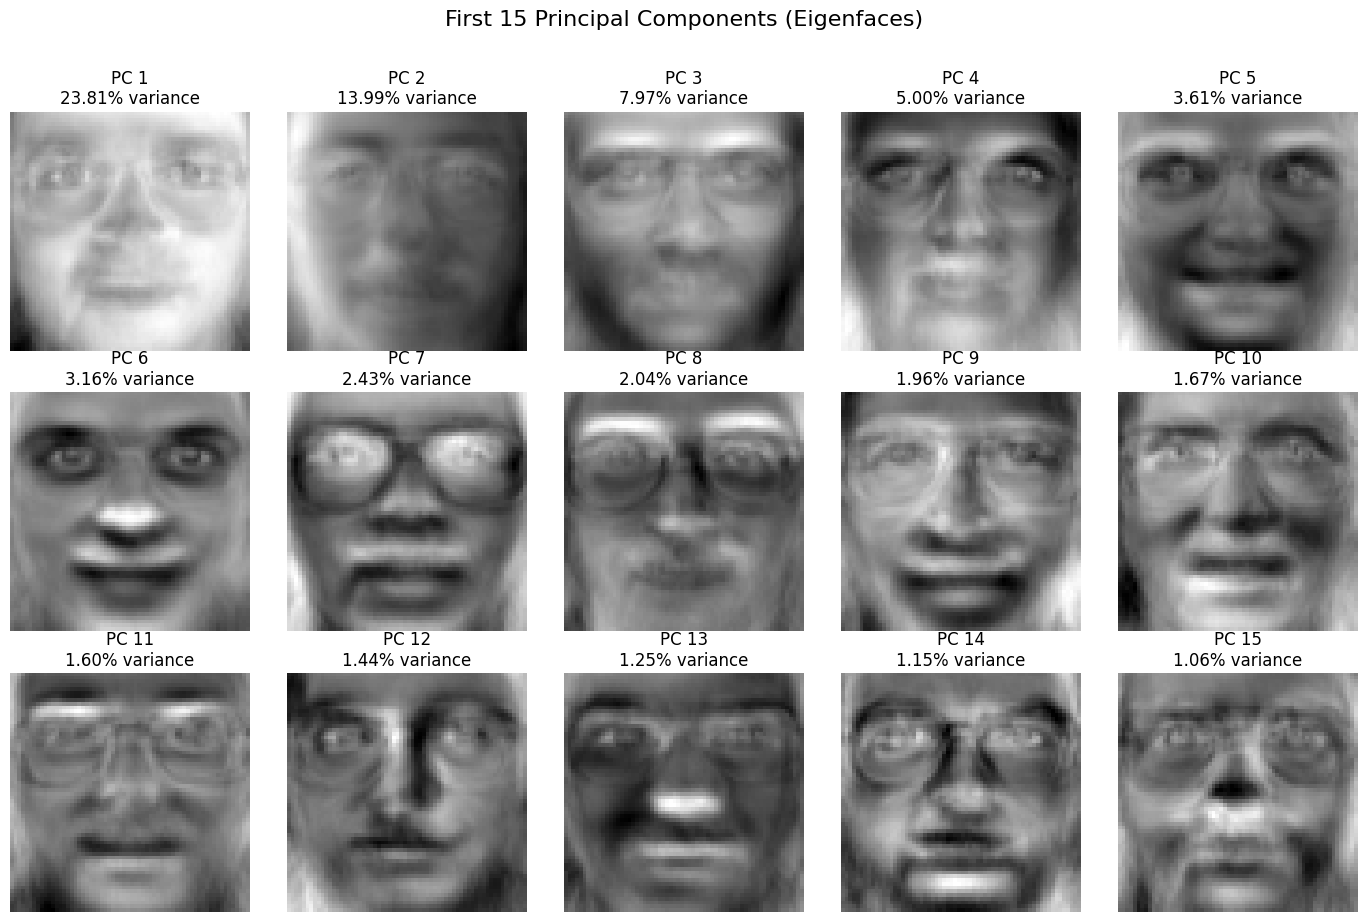

In [4]:
import numpy as np
import matplotlib.pyplot as plt

components = pca.components_
variance_pct = pca.explained_variance_ratio_ * 100

print(f"Shape of components matrix: {components.shape}")
print(f"Variance explained by the first 15 components: {variance_pct[:15].sum():.2f}%")

fig, axes = plt.subplots(3, 5, figsize=(14, 9))

for i, ax in enumerate(axes.ravel()):
    eigenface = components[i].reshape(64, 64)

    ax.imshow(eigenface, cmap='gray')
    ax.set_title(f'PC {i + 1}\n{variance_pct[i]:.2f}% variance')
    ax.axis('off')

plt.suptitle('First 15 Principal Components (Eigenfaces)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

#### **Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model)** Perform a stratified train/test split (80/20). Train a LogisticRegression classifier on:

1. The raw 4,096-dimensional feature vectors.
2. The PCA-reduced feature vectors using the 95% variance threshold fitted strictly on the training set

Evaluate and print the test accuracy and training time for both, and visualize the performance comparison in a dual-axis bar plot (Accuracy vs. Training Time).

This cell compares a linear classifier trained on raw pixels against one trained on PCA-reduced features. It does this in five steps:

1. Split the data. `train_test_split(..., test_size=0.2, stratify=y)` holds out 20% of the images for testing. `stratify=y` keeps the same proportion of each subject in both sets, so all 40 subjects appear in training and testing (8 training and 2 test images each).
2. Train on raw features. `LogisticRegression` is fitted on the 4,096-pixel vectors, and we record the training time with `time.time()` and the accuracy on the held-out test set.
3. Fit PCA on the training set only. `PCA(n_components=0.95)` automatically keeps the smallest number of components that explain 95% of the training variance. `fit_transform` learns the components from the training data, and `transform` applies those same components to the test data. Fitting PCA on the test set would leak information about it into training.
4. Train on PCA features. A second `LogisticRegression` is fitted on the reduced vectors. The recorded time includes the PCA fitting, so the comparison is fair.
5. Plot the comparison. The dual-axis bar chart shows test accuracy (blue, left axis) and training time (orange, right axis) for both models, with the values labeled above each bar.

Training set: (320, 4096), Test set: (80, 4096)

Training classifier on raw features...
Raw Features Accuracy: 0.9750 (Training time: 28.51s)

Training classifier on PCA-reduced features (95% variance)...
Number of PCA components retained: 111
PCA-Reduced Features Accuracy: 0.9750 (Training time: 0.55s)


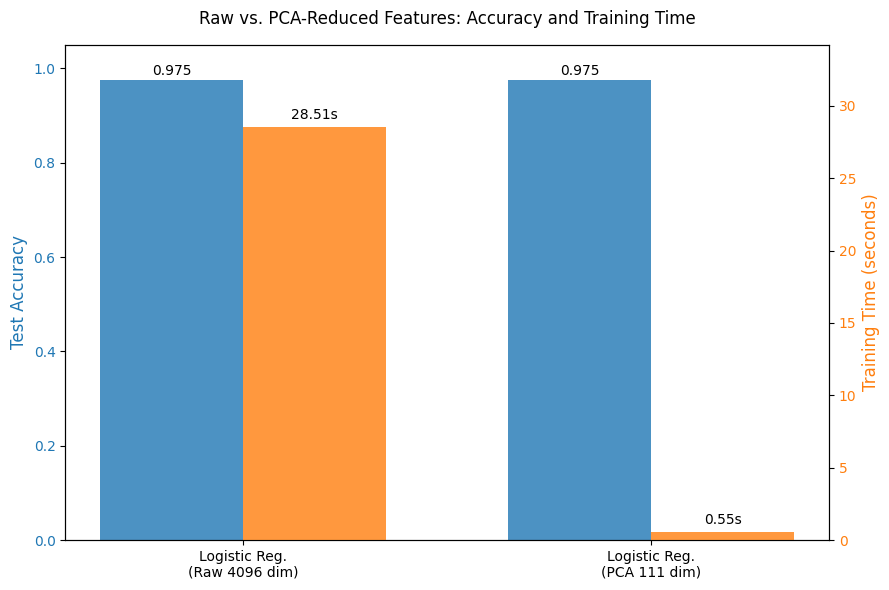

In [5]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Stratified 80/20 split (each subject keeps the same train/test proportion)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

# 1. Train classifier on raw features (4,096 dimensions)
print("\nTraining classifier on raw features...")
start_time = time.time()
clf_raw = LogisticRegression(max_iter=1000, random_state=42)
clf_raw.fit(X_train, y_train)
raw_time = time.time() - start_time

raw_accuracy = accuracy_score(y_test, clf_raw.predict(X_test))
print(f"Raw Features Accuracy: {raw_accuracy:.4f} (Training time: {raw_time:.2f}s)")

# 2. Train classifier on PCA-reduced features (95% variance), PCA fitted on training data only
print("\nTraining classifier on PCA-reduced features (95% variance)...")
start_time = time.time()

pca_95 = PCA(n_components=0.95)
X_train_pca = pca_95.fit_transform(X_train)
X_test_pca = pca_95.transform(X_test)

clf_pca = LogisticRegression(max_iter=1000, random_state=42)
clf_pca.fit(X_train_pca, y_train)
pca_time = time.time() - start_time

pca_accuracy = accuracy_score(y_test, clf_pca.predict(X_test_pca))
print(f"Number of PCA components retained: {pca_95.n_components_}")
print(f"PCA-Reduced Features Accuracy: {pca_accuracy:.4f} (Training time: {pca_time:.2f}s)")

models = [f'Logistic Reg.\n(Raw {X.shape[1]} dim)',
          f'Logistic Reg.\n(PCA {pca_95.n_components_} dim)']
accuracies = [raw_accuracy, pca_accuracy]
train_times = [raw_time, pca_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(9, 6))

color = 'tab:blue'
ax1.set_ylabel('Test Accuracy', color=color, fontsize=12)
ax1.bar(x - width/2, accuracies, width, color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.05)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
ax2.bar(x + width/2, train_times, width, color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max(train_times) * 1.2)

for i in range(len(models)):
    ax1.text(x[i] - width/2, accuracies[i] + 0.01, f'{accuracies[i]:.3f}', ha='center')
    ax2.text(x[i] + width/2, train_times[i] + max(train_times) * 0.02, f'{train_times[i]:.2f}s', ha='center')

ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Raw vs. PCA-Reduced Features: Accuracy and Training Time', fontsize=12, pad=15)
fig.tight_layout()
plt.show()

#### **Task 6: Non-Linear Classification (Kernel SVM)** Train a SVC with an RBF kernel on the PCA-reduced features (95% variance). Record its training time and test accuracy, and plot a confusion matrix or classification summary comparing its predictions against the linear baseline.

This cell trains a non-linear classifier on the PCA-reduced faces and compares it to the linear baseline. It does this in five steps:

1. Train the SVM. `SVC(kernel='rbf')` is fitted on `X_train_pca`, the same 95%-variance features used for logistic regression. We record the training time with `time.time()`.
2. Predict with both models. The SVM and the logistic regression model from Section 5 each predict a subject ID for every image in the same held-out test set, so any difference comes from the model and not from the data.
3. Compute accuracy and macro F1. Accuracy is the fraction of faces identified correctly. Macro F1 averages the per-subject F1 scores equally, so it shows whether performance is even across subjects.
4. Count fully correct subjects. In the confusion matrix, each row is a true subject and each column a predicted subject. Comparing the diagonal to the row total shows how many subjects had both of their test images classified correctly.
5. Plot the confusion matrices. The two heatmaps sit side by side with the same color scale. A bright diagonal means correct predictions, and bright cells off the diagonal show which subjects were confused with one another.

Training RBF SVM on PCA-reduced features (95% variance)...
RBF SVM Accuracy: 0.9500 (Training time: 0.03s)
Linear Baseline (Logistic Reg. + PCA) Accuracy: 0.9750

--- Classification Summary ---
Logistic Reg. (PCA)    accuracy: 0.9750 | macro F1: 0.9733 | subjects fully correct: 38/40
RBF SVM (PCA)          accuracy: 0.9500 | macro F1: 0.9467 | subjects fully correct: 36/40


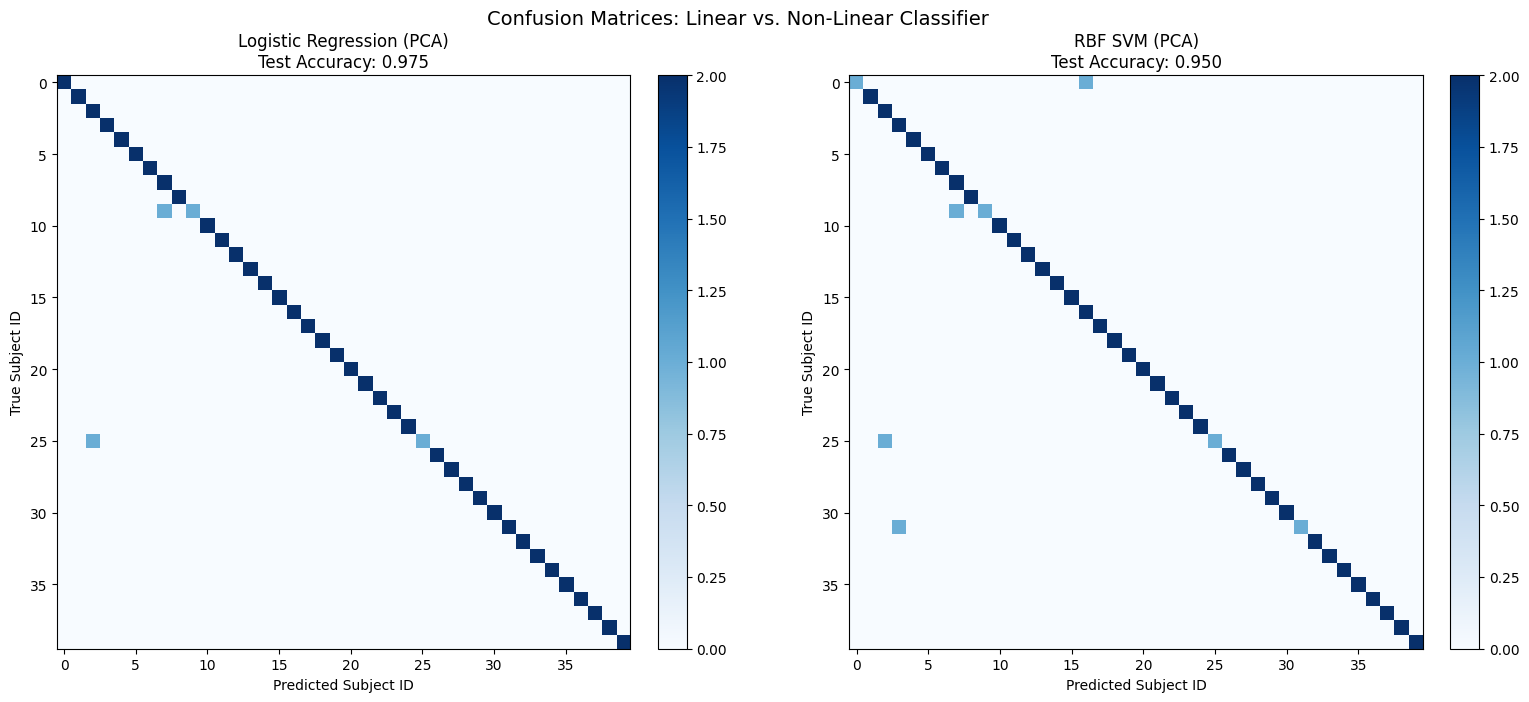

In [6]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

print("Training RBF SVM on PCA-reduced features (95% variance)...")
start_time = time.time()
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train_pca, y_train)
svm_time = time.time() - start_time

y_pred_svm = svm_rbf.predict(X_test_pca)
y_pred_lin = clf_pca.predict(X_test_pca)

svm_accuracy = accuracy_score(y_test, y_pred_svm)
lin_accuracy = accuracy_score(y_test, y_pred_lin)

print(f"RBF SVM Accuracy: {svm_accuracy:.4f} (Training time: {svm_time:.2f}s)")
print(f"Linear Baseline (Logistic Reg. + PCA) Accuracy: {lin_accuracy:.4f}")

print("\n--- Classification Summary ---")
for name, y_pred in [('Logistic Reg. (PCA)', y_pred_lin), ('RBF SVM (PCA)', y_pred_svm)]:
    macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(40))
    subjects_all_correct = np.sum(np.diag(cm) == cm.sum(axis=1))
    print(f"{name:<22} accuracy: {accuracy_score(y_test, y_pred):.4f} | "
          f"macro F1: {macro_f1:.4f} | subjects fully correct: {subjects_all_correct}/40")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, name, y_pred in zip(
    axes,
    ['Logistic Regression (PCA)', 'RBF SVM (PCA)'],
    [y_pred_lin, y_pred_svm]
):
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(40))
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=2)
    ax.set_title(f'{name}\nTest Accuracy: {accuracy_score(y_test, y_pred):.3f}')
    ax.set_xlabel('Predicted Subject ID')
    ax.set_ylabel('True Subject ID')
    ax.set_xticks(np.arange(0, 40, 5))
    ax.set_yticks(np.arange(0, 40, 5))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Confusion Matrices: Linear vs. Non-Linear Classifier', fontsize=14)
plt.tight_layout()
plt.show()

#### **Task 7: Ensemble Classification on PCA Features** Construct a VotingClassifier (soft voting) combining a Polynomial Kernel SVM (degree=2), an RBF Kernel SVM, and a RandomForestClassifier (n_estimators=100). Train the ensemble on the PCA-reduced features, record training time and accuracy, and compare its performance against the single linear and non-linear models.

This cell builds a soft-voting ensemble of three different classifiers and compares it with the earlier models. It does this in five steps:

1. Define the members. A degree-2 polynomial SVM, an RBF SVM, and a Random Forest with 100 trees. The two SVMs use `probability=True` so they can output class probabilities, which soft voting requires.
2. Combine them. `VotingClassifier(voting='soft')` asks each member for its predicted probability for every subject, averages those probabilities, and predicts the subject with the highest average. This lets a confident model outweigh an uncertain one.
3. Train the ensemble. `fit` trains all three members on the same PCA-reduced training features, and we record the total time.
4. Evaluate. We compute the ensemble's test accuracy, then use `named_estimators_` to get the accuracy of each fitted member on its own. This shows whether combining them helps beyond the best single member.
5. Plot the comparison. A dual-axis bar chart shows test accuracy (blue, left axis) and training time (orange, right axis) for the raw logistic regression, PCA logistic regression, RBF SVM, and ensemble, with the values labeled above each bar.

Training Ensemble Classifier on PCA-reduced features (95% variance)...
Ensemble Classifier Accuracy: 0.9750 (Training time: 1.33s)

Individual ensemble members:
  poly_svm       accuracy: 0.7875
  rbf_svm        accuracy: 0.9500
  random_forest  accuracy: 0.9625


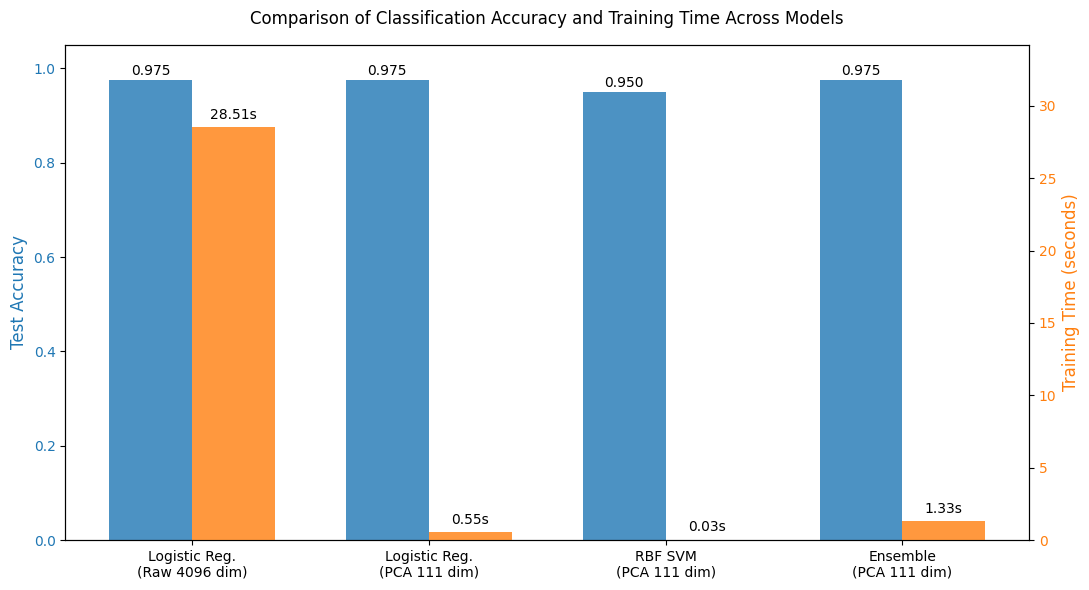

In [7]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score

poly_svm = SVC(kernel='poly', degree=2, probability=True, random_state=42)
rbf_svm = SVC(kernel='rbf', probability=True, random_state=42)
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)

ensemble_clf = VotingClassifier(
    estimators=[
        ('poly_svm', poly_svm),
        ('rbf_svm', rbf_svm),
        ('random_forest', random_forest)
    ],
    voting='soft'
)

print("Training Ensemble Classifier on PCA-reduced features (95% variance)...")
start_time = time.time()
ensemble_clf.fit(X_train_pca, y_train)
ensemble_time = time.time() - start_time

ensemble_accuracy = accuracy_score(y_test, ensemble_clf.predict(X_test_pca))
print(f"Ensemble Classifier Accuracy: {ensemble_accuracy:.4f} (Training time: {ensemble_time:.2f}s)")

print("\nIndividual ensemble members:")
for name, fitted_model in ensemble_clf.named_estimators_.items():
    acc = accuracy_score(y_test, fitted_model.predict(X_test_pca))
    print(f"  {name:<14} accuracy: {acc:.4f}")

models = [
    f'Logistic Reg.\n(Raw {X.shape[1]} dim)',
    f'Logistic Reg.\n(PCA {pca_95.n_components_} dim)',
    f'RBF SVM\n(PCA {pca_95.n_components_} dim)',
    f'Ensemble\n(PCA {pca_95.n_components_} dim)'
]
accuracies = [raw_accuracy, pca_accuracy, svm_accuracy, ensemble_accuracy]
train_times = [raw_time, pca_time, svm_time, ensemble_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(11, 6))

color = 'tab:blue'
ax1.set_ylabel('Test Accuracy', color=color, fontsize=12)
ax1.bar(x - width/2, accuracies, width, color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.05)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
ax2.bar(x + width/2, train_times, width, color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max(train_times) * 1.2)

# Label each bar with its value
for i in range(len(models)):
    ax1.text(x[i] - width/2, accuracies[i] + 0.01, f'{accuracies[i]:.3f}', ha='center')
    ax2.text(x[i] + width/2, train_times[i] + max(train_times) * 0.02, f'{train_times[i]:.2f}s', ha='center')

ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Comparison of Classification Accuracy and Training Time Across Models', fontsize=12, pad=15)
fig.tight_layout()
plt.show()

#### **Task 8: Comprehensive Comparative Evaluation** Create a single summary bar plot comparing Accuracy (primary y-axis) and Training Time in seconds (secondary y-axis) across all four model configurations:

1. Logistic Regression (Raw Features)
2. Logistic Regression (PCA-Reduced)
3. Support Vector Classifier with RBF Kernel (PCA-Reduced)
4. Soft Voting Ensemble (PCA-Reduced)

This cell brings together the results from all four classifiers and compares them in one summary. It does this in four steps:

1. Collect the results. The test accuracies and training times saved in Sections 5, 6, and 7 are placed into a Pandas DataFrame, with one row per model. The number of PCA components comes from `pca_95.n_components_`, so the labels always match the actual run.
2. Print the summary table. This gives the exact values for each model, which are easier to read than bar heights.
3. Draw the accuracy bars. The blue bars use the left (primary) y-axis, scaled from 0 to 1 so they read as a fraction of correct predictions.
4. Draw the training-time bars. `ax1.twinx()` creates a second y-axis that shares the same x-axis, and the orange bars use it for time in seconds. Each bar is labeled with its value, and a combined legend covers both axes.

                             Model  Test Accuracy  Training Time (s)
      Logistic Reg. (Raw 4096 dim)         0.9750            28.5143
       Logistic Reg. (PCA 111 dim)         0.9750             0.5500
             SVC RBF (PCA 111 dim)         0.9500             0.0297
Soft Voting Ensemble (PCA 111 dim)         0.9750             1.3288


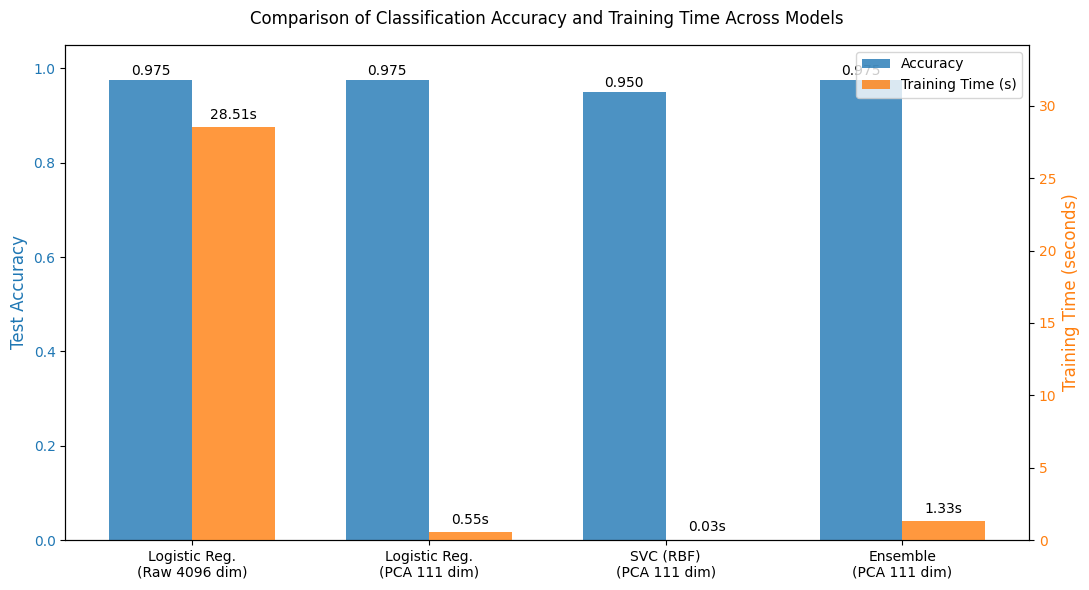

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

n_pca = pca_95.n_components_

results = pd.DataFrame({
    'Model': [
        f'Logistic Reg. (Raw {X.shape[1]} dim)',
        f'Logistic Reg. (PCA {n_pca} dim)',
        f'SVC RBF (PCA {n_pca} dim)',
        f'Soft Voting Ensemble (PCA {n_pca} dim)'
    ],
    'Test Accuracy': [raw_accuracy, pca_accuracy, svm_accuracy, ensemble_accuracy],
    'Training Time (s)': [raw_time, pca_time, svm_time, ensemble_time]
})

print(results.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

models = [
    f'Logistic Reg.\n(Raw {X.shape[1]} dim)',
    f'Logistic Reg.\n(PCA {n_pca} dim)',
    f'SVC (RBF)\n(PCA {n_pca} dim)',
    f'Ensemble\n(PCA {n_pca} dim)'
]
accuracies = results['Test Accuracy'].values
train_times = results['Training Time (s)'].values

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(11, 6))

color = 'tab:blue'
ax1.set_ylabel('Test Accuracy', color=color, fontsize=12)
ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.05)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
ax2.bar(x + width/2, train_times, width, label='Training Time (s)', color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max(train_times) * 1.2)

for i in range(len(models)):
    ax1.text(x[i] - width/2, accuracies[i] + 0.01, f'{accuracies[i]:.3f}', ha='center')
    ax2.text(x[i] + width/2, train_times[i] + max(train_times) * 0.02, f'{train_times[i]:.2f}s', ha='center')

ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right')

plt.title('Comparison of Classification Accuracy and Training Time Across Models', fontsize=12, pad=15)
fig.tight_layout()
plt.show()